Normas: 1.0 1.0
Producto interno: 0.0


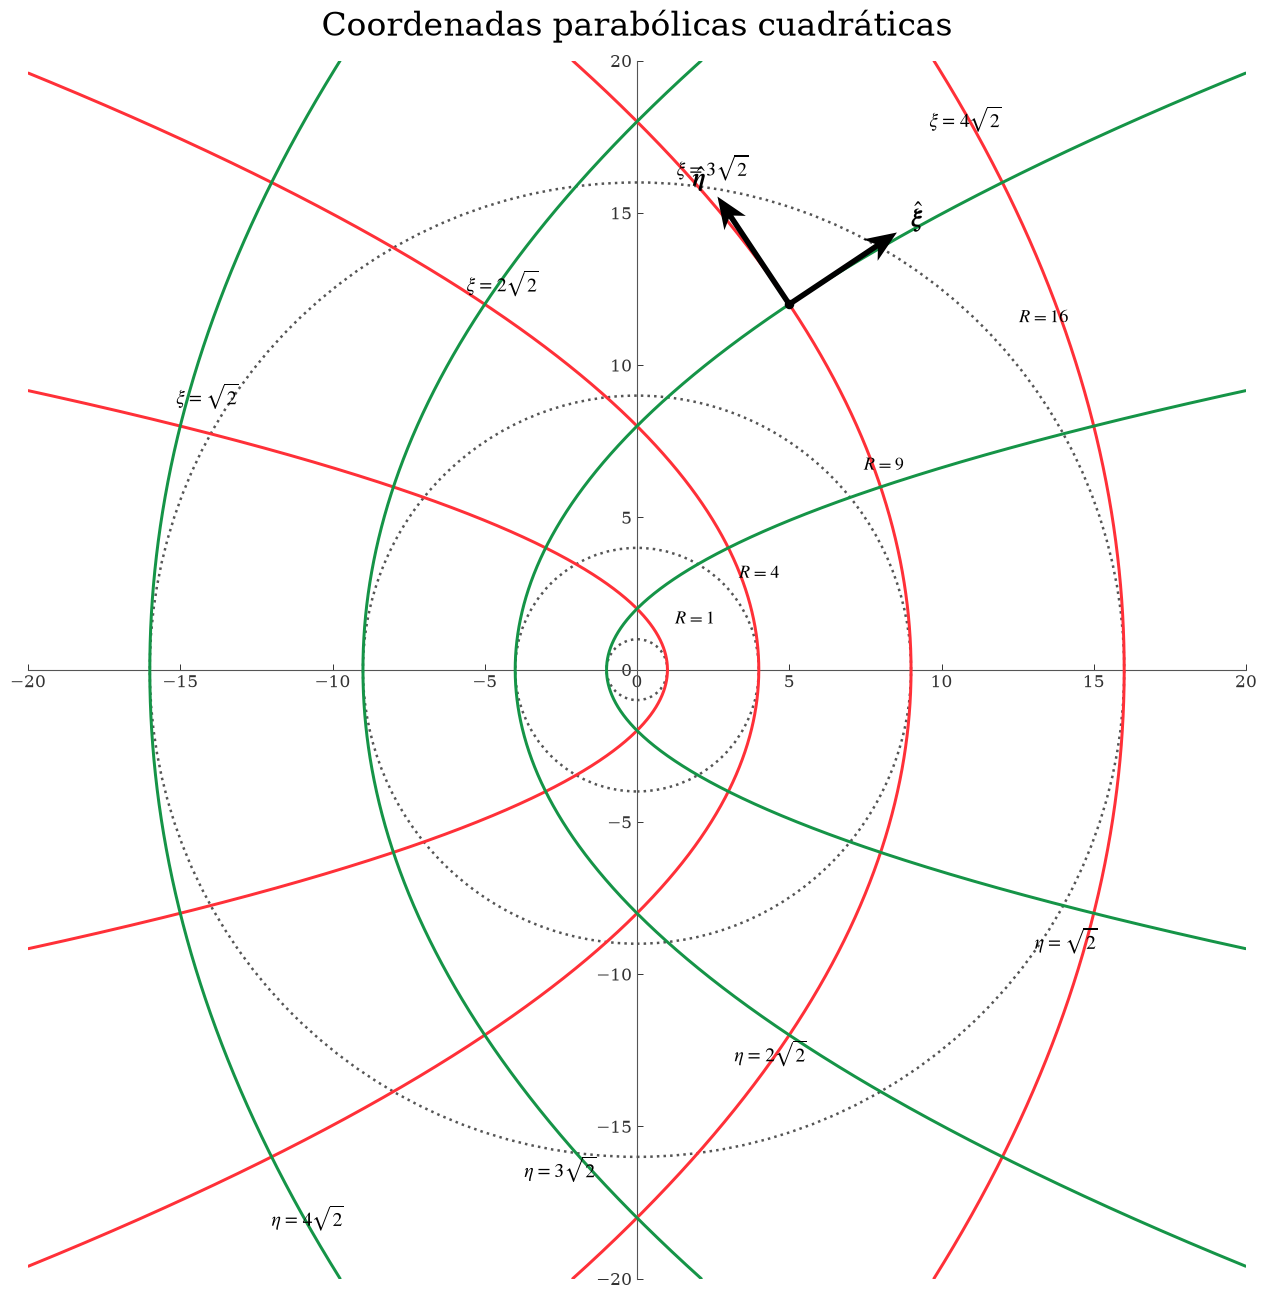

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})


DOMAIN_LIMIT = 20.0
OUTPUT_DPI = 600

OUTPUT_DIRECTORY = "Weber_Poster"

COEFFICIENTS = np.array([
    1,
    2,
    3,
    4
])

XI_VALUES = (
    COEFFICIENTS
    * np.sqrt(2.0)
)

ETA_VALUES = (
    COEFFICIENTS
    * np.sqrt(2.0)
)

CIRCLE_RADII = (
    COEFFICIENTS**2
)

Y_CURVE = np.linspace(
    -60.0,
    60.0,
    10000
)


# ============================================================
# POSICIONES MANUALES DE TODAS LAS ETIQUETAS
#
# Formato:
#
#     nombre: (posición_x, posición_y)
#
# Cambia directamente cualquier pareja de números.
# ============================================================

LABEL_POSITIONS = {

    # Curvas xi = constante

    "xi_1": (-14.1, 8.5),
    "xi_2": (-4.4, 12.2),
    "xi_3": (2.5, 16.0),
    "xi_4": (10.8, 17.6),

    # Curvas eta = constante

    "eta_1": (14.1, -8.5),
    "eta_2": (4.4, -12.2),
    "eta_3": (-2.5, -16.0),
    "eta_4": (-10.8, -17.6),

    # Círculos R = constante

    "R_1": (1.25, 1.35),
    "R_4": (3.35, 2.85),
    "R_9": (7.45, 6.40),
    "R_16": (12.55, 11.25),

    # Etiquetas de los vectores unitarios
    # Estas son posiciones absolutas.

    "xi_hat": (9.20, 14.85),
    "eta_hat": (2.05, 16.10)
}


# ============================================================
# CONFIGURACIÓN DE LOS VECTORES UNITARIOS
# ============================================================

UNIT_VECTOR_SETTINGS = {

    # El punto corresponde a la intersección:
    #
    # xi = 3 sqrt(2)
    # eta = 2 sqrt(2)

    "xi_coefficient": 3,
    "eta_coefficient": 2,

    "arrow_length": 4.25,
    "point_size": 34,
    "arrow_width": 0.0045
}


def coordinate_label(
    symbol,
    coefficient
):
    if coefficient == 1:
        return rf"${symbol}=\sqrt{{2}}$"

    return (
        rf"${symbol}="
        rf"{coefficient}\sqrt{{2}}$"
    )


def quadratic_xi_curve(
    xi_value,
    y
):
    return (
        xi_value**2
        - (y / xi_value)**2
    ) / 2.0


def quadratic_eta_curve(
    eta_value,
    y
):
    return (
        (y / eta_value)**2
        - eta_value**2
    ) / 2.0


def visible_part(
    x,
    y,
    limit
):
    return (
        (x >= -limit)
        & (x <= limit)
        & (y >= -limit)
        & (y <= limit)
    )


def save_quadratic_parabolic_grid(
    domain_limit=DOMAIN_LIMIT,
    dpi=OUTPUT_DPI,
    output_directory=OUTPUT_DIRECTORY,
    show=True
):
    os.makedirs(
        output_directory,
        exist_ok=True
    )

    fig, ax = plt.subplots(
        figsize=(14.0, 14.0),
        facecolor="white"
    )

    fig.subplots_adjust(
        left=0.055,
        right=0.995,
        bottom=0.055,
        top=0.925
    )

    # Curvas xi = constante

    for coefficient, xi_value in zip(
        COEFFICIENTS,
        XI_VALUES
    ):
        x_curve = quadratic_xi_curve(
            xi_value,
            Y_CURVE
        )

        visible = visible_part(
            x_curve,
            Y_CURVE,
            domain_limit
        )

        ax.plot(
            x_curve[visible],
            Y_CURVE[visible],
            color="#ff3038",
            linewidth=2.15,
            solid_capstyle="round",
            zorder=4
        )

    # Curvas eta = constante

    for coefficient, eta_value in zip(
        COEFFICIENTS,
        ETA_VALUES
    ):
        x_curve = quadratic_eta_curve(
            eta_value,
            Y_CURVE
        )

        visible = visible_part(
            x_curve,
            Y_CURVE,
            domain_limit
        )

        ax.plot(
            x_curve[visible],
            Y_CURVE[visible],
            color="#159447",
            linewidth=2.15,
            solid_capstyle="round",
            zorder=4
        )

    # Círculos R = constante

    for radius in CIRCLE_RADII:
        circle = plt.Circle(
            (0.0, 0.0),
            radius,
            color="#555555",
            fill=False,
            linestyle=":",
            linewidth=1.8,
            zorder=2
        )

        ax.add_artist(circle)

    # Etiquetas xi = constante

    for coefficient in COEFFICIENTS:
        label_position = (
            LABEL_POSITIONS[
                f"xi_{coefficient}"
            ]
        )

        ax.text(
            label_position[0],
            label_position[1],
            coordinate_label(
                r"\xi",
                coefficient
            ),
            fontsize=14,
            color="black",
            ha="center",
            va="bottom",
            fontweight="normal",
            zorder=10
        )

    # Etiquetas eta = constante

    for coefficient in COEFFICIENTS:
        label_position = (
            LABEL_POSITIONS[
                f"eta_{coefficient}"
            ]
        )

        ax.text(
            label_position[0],
            label_position[1],
            coordinate_label(
                r"\eta",
                coefficient
            ),
            fontsize=14,
            color="black",
            ha="center",
            va="top",
            fontweight="normal",
            zorder=10
        )

    # Etiquetas R = constante

    for radius in CIRCLE_RADII:
        label_position = (
            LABEL_POSITIONS[
                f"R_{radius}"
            ]
        )

        ax.text(
            label_position[0],
            label_position[1],
            rf"$R={radius}$",
            fontsize=13,
            color="black",
            ha="left",
            va="bottom",
            fontweight="normal",
            zorder=9
        )

    # Vectores unitarios

    xi_selected = (
        UNIT_VECTOR_SETTINGS["xi_coefficient"]
        * np.sqrt(2.0)
    )

    eta_selected = (
        UNIT_VECTOR_SETTINGS["eta_coefficient"]
        * np.sqrt(2.0)
    )

    center_x = (
        xi_selected**2
        - eta_selected**2
    ) / 2.0

    center_y = (
        xi_selected
        * eta_selected
    )

    scale_factor = np.sqrt(
        xi_selected**2
        + eta_selected**2
    )

    xi_hat = np.array([
        xi_selected,
        eta_selected
    ]) / scale_factor

    eta_hat = np.array([
        -eta_selected,
        xi_selected
    ]) / scale_factor

    arrow_length = (
        UNIT_VECTOR_SETTINGS["arrow_length"]
    )

    ax.scatter(
        center_x,
        center_y,
        color="black",
        s=UNIT_VECTOR_SETTINGS["point_size"],
        zorder=11
    )

    ax.quiver(
        center_x,
        center_y,
        arrow_length * xi_hat[0],
        arrow_length * xi_hat[1],
        color="black",
        angles="xy",
        scale_units="xy",
        scale=1,
        width=UNIT_VECTOR_SETTINGS["arrow_width"],
        headwidth=4.7,
        headlength=5.8,
        zorder=11
    )

    ax.quiver(
        center_x,
        center_y,
        arrow_length * eta_hat[0],
        arrow_length * eta_hat[1],
        color="black",
        angles="xy",
        scale_units="xy",
        scale=1,
        width=UNIT_VECTOR_SETTINGS["arrow_width"],
        headwidth=4.7,
        headlength=5.8,
        zorder=11
    )

    # Posiciones manuales y absolutas
    # de las etiquetas de los vectores.

    xi_hat_label = (
        LABEL_POSITIONS["xi_hat"]
    )

    eta_hat_label = (
        LABEL_POSITIONS["eta_hat"]
    )

    ax.text(
        xi_hat_label[0],
        xi_hat_label[1],
        r"$\hat{\boldsymbol{\xi}}$",
        color="black",
        fontsize=18,
        ha="center",
        va="center",
        fontweight="normal",
        zorder=12
    )

    ax.text(
        eta_hat_label[0],
        eta_hat_label[1],
        r"$\hat{\boldsymbol{\eta}}$",
        color="black",
        fontsize=18,
        ha="center",
        va="center",
        fontweight="normal",
        zorder=12
    )

    print(
        "Normas:",
        np.linalg.norm(xi_hat),
        np.linalg.norm(eta_hat)
    )

    print(
        "Producto interno:",
        np.dot(xi_hat, eta_hat)
    )

    # Ejes cartesianos

    ax.spines["left"].set_position(
        "zero"
    )

    ax.spines["bottom"].set_position(
        "zero"
    )

    ax.spines["left"].set_linewidth(
        0.8
    )

    ax.spines["bottom"].set_linewidth(
        0.8
    )

    ax.spines["left"].set_color(
        "#555555"
    )

    ax.spines["bottom"].set_color(
        "#555555"
    )

    ax.spines["right"].set_color(
        "none"
    )

    ax.spines["top"].set_color(
        "none"
    )

    ax.xaxis.set_ticks_position(
        "bottom"
    )

    ax.yaxis.set_ticks_position(
        "left"
    )

    ax.set_xlim(
        -domain_limit,
        domain_limit
    )

    ax.set_ylim(
        -domain_limit,
        domain_limit
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.grid(False)

    ax.tick_params(
        axis="both",
        colors="#333333",
        labelsize=12,
        direction="in",
        length=4,
        width=0.7
    )

    # Título sin negritas

    ax.set_title(
        "Coordenadas parabólicas cuadráticas",
        fontsize=24,
        fontweight="normal",
        pad=18
    )

    png_path = os.path.join(
        output_directory,
        "grid_parabolico_cuadratico_rango_20.png"
    )

    pdf_path = os.path.join(
        output_directory,
        "grid_parabolico_cuadratico_rango_20.pdf"
    )

    svg_path = os.path.join(
        output_directory,
        "grid_parabolico_cuadratico_rango_20.svg"
    )

    save_options = {
        "facecolor": "white",
        "edgecolor": "none",
        "bbox_inches": "tight",
        "pad_inches": 0.03
    }

    fig.savefig(
        png_path,
        dpi=dpi,
        **save_options
    )

    fig.savefig(
        pdf_path,
        dpi=dpi,
        **save_options
    )

    fig.savefig(
        svg_path,
        dpi=dpi,
        **save_options
    )

    if show:
        plt.show()
    plt.close(fig)
    return png_path, pdf_path, svg_path


grid_files = save_quadratic_parabolic_grid(
    domain_limit=20.0, dpi=600,
    output_directory="Weber_Poster", show=True
)

Normas: 1.0 1.0
Producto interno: 0.0


Archivos guardados:
Weber_Poster/grid_parabolico_cuadratico_rango_20.png
Weber_Poster/grid_parabolico_cuadratico_rango_20.pdf
Weber_Poster/grid_parabolico_cuadratico_rango_20.svg


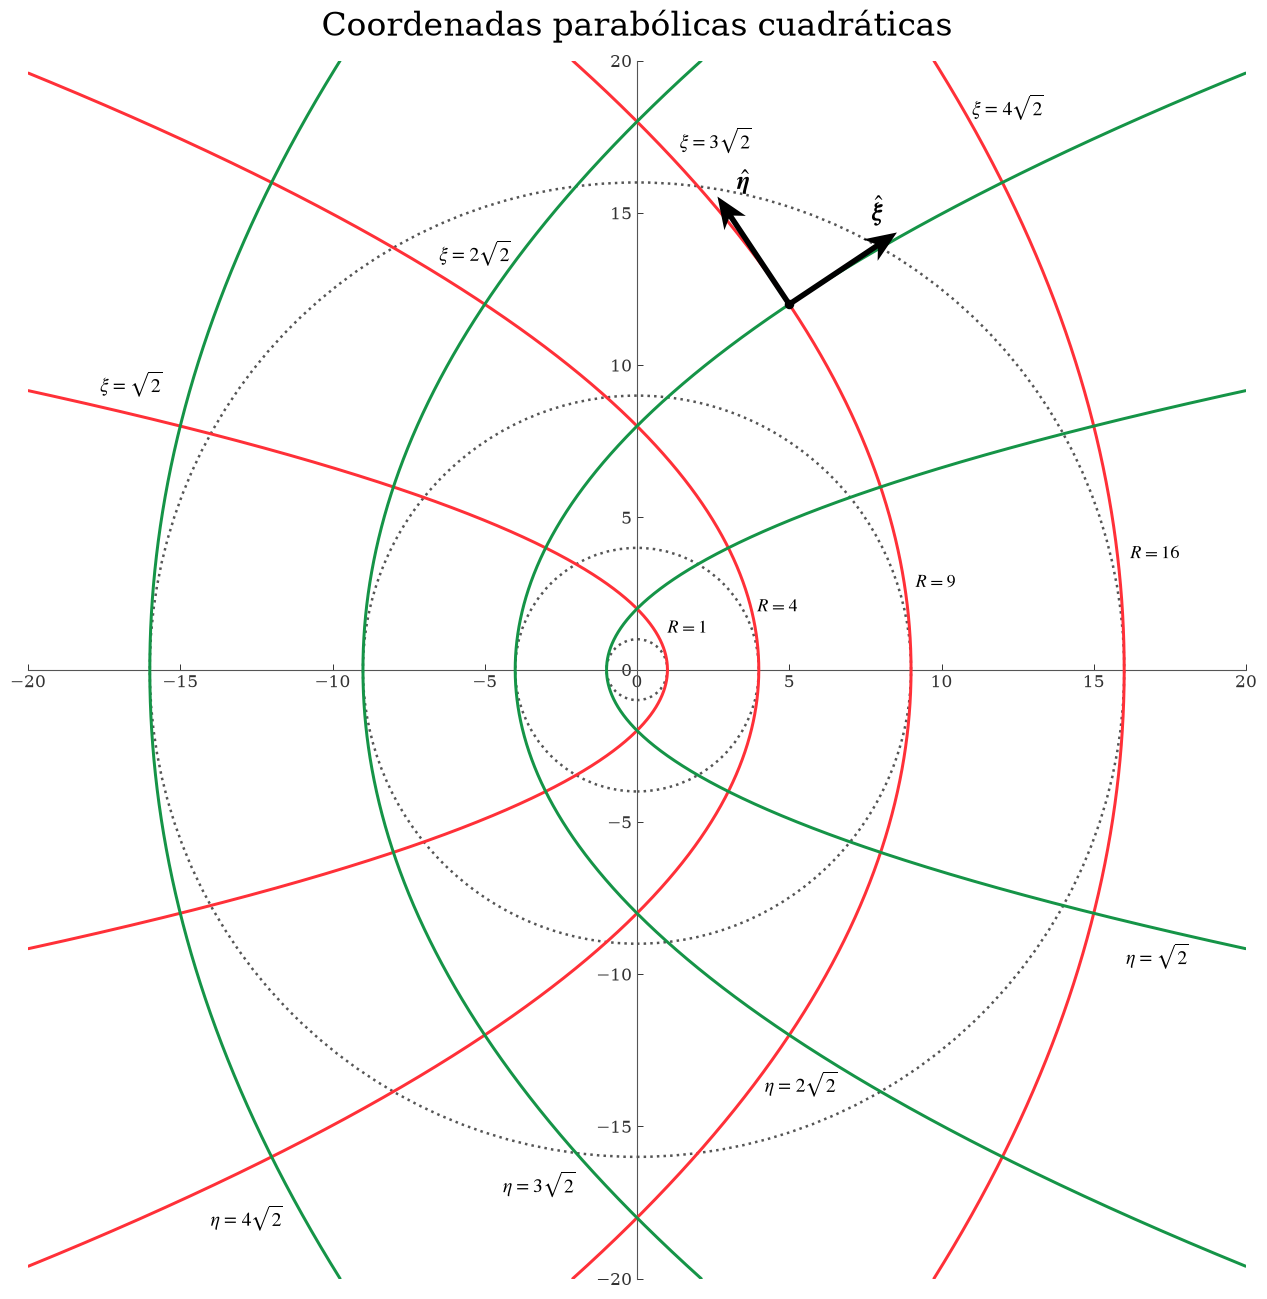

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})


DOMAIN_LIMIT = 20.0
OUTPUT_DPI = 600

OUTPUT_DIRECTORY = "Weber_Poster"

COEFFICIENTS = np.array([
    1,
    2,
    3,
    4
])

XI_VALUES = (
    COEFFICIENTS
    * np.sqrt(2.0)
)

ETA_VALUES = (
    COEFFICIENTS
    * np.sqrt(2.0)
)

CIRCLE_RADII = (
    COEFFICIENTS**2
)

Y_CURVE = np.linspace(
    -60.0,
    60.0,
    10000
)


# ============================================================
# POSICIONES MANUALES DE TODAS LAS ETIQUETAS
#
# Formato:
#
#     nombre: (posición_x, posición_y)
#
# Cambia directamente cualquier pareja de números.
# ============================================================

LABEL_POSITIONS = {

    # Curvas xi = constante

    "xi_1": (-16.6, 8.9),
    "xi_2": (-5.3, 13.2),
    "xi_3": (2.6, 16.9),
    "xi_4": (12.2, 17.99),

    # Curvas eta = constante

    "eta_1": (17.1, -9.0),
    "eta_2": (5.4, -13.2),
    "eta_3": (-3.2, -16.5),
    "eta_4": (-12.8, -17.6),

    # Círculos R = constante

    "R_1": (1.0, 1.05),
    "R_4": (3.95, 1.75),
    "R_9": (9.15, 2.55),
    "R_16": (16.2, 3.5),

    # Etiquetas de los vectores unitarios
    # Estas son posiciones absolutas.

    "xi_hat": (7.90, 15.05),
    "eta_hat": (3.5, 16.00)
}


# ============================================================
# CONFIGURACIÓN DE LOS VECTORES UNITARIOS
# ============================================================

UNIT_VECTOR_SETTINGS = {

    # El punto corresponde a la intersección:
    #
    # xi = 3 sqrt(2)
    # eta = 2 sqrt(2)

    "xi_coefficient": 3,
    "eta_coefficient": 2,

    "arrow_length": 4.25,
    "point_size": 34,
    "arrow_width": 0.0045
}


def coordinate_label(
    symbol,
    coefficient
):
    if coefficient == 1:
        return rf"${symbol}=\sqrt{{2}}$"

    return (
        rf"${symbol}="
        rf"{coefficient}\sqrt{{2}}$"
    )


def quadratic_xi_curve(
    xi_value,
    y
):
    return (
        xi_value**2
        - (y / xi_value)**2
    ) / 2.0


def quadratic_eta_curve(
    eta_value,
    y
):
    return (
        (y / eta_value)**2
        - eta_value**2
    ) / 2.0


def visible_part(
    x,
    y,
    limit
):
    return (
        (x >= -limit)
        & (x <= limit)
        & (y >= -limit)
        & (y <= limit)
    )


def save_quadratic_parabolic_grid(
    domain_limit=DOMAIN_LIMIT,
    dpi=OUTPUT_DPI,
    output_directory=OUTPUT_DIRECTORY,
    show=True
):
    os.makedirs(
        output_directory,
        exist_ok=True
    )

    fig, ax = plt.subplots(
        figsize=(14.0, 14.0),
        facecolor="white"
    )

    fig.subplots_adjust(
        left=0.055,
        right=0.995,
        bottom=0.055,
        top=0.925
    )

    # Curvas xi = constante

    for coefficient, xi_value in zip(
        COEFFICIENTS,
        XI_VALUES
    ):
        x_curve = quadratic_xi_curve(
            xi_value,
            Y_CURVE
        )

        visible = visible_part(
            x_curve,
            Y_CURVE,
            domain_limit
        )

        ax.plot(
            x_curve[visible],
            Y_CURVE[visible],
            color="#ff3038",
            linewidth=2.15,
            solid_capstyle="round",
            zorder=4
        )

    # Curvas eta = constante

    for coefficient, eta_value in zip(
        COEFFICIENTS,
        ETA_VALUES
    ):
        x_curve = quadratic_eta_curve(
            eta_value,
            Y_CURVE
        )

        visible = visible_part(
            x_curve,
            Y_CURVE,
            domain_limit
        )

        ax.plot(
            x_curve[visible],
            Y_CURVE[visible],
            color="#159447",
            linewidth=2.15,
            solid_capstyle="round",
            zorder=4
        )

    # Círculos R = constante

    for radius in CIRCLE_RADII:
        circle = plt.Circle(
            (0.0, 0.0),
            radius,
            color="#555555",
            fill=False,
            linestyle=":",
            linewidth=1.8,
            zorder=2
        )

        ax.add_artist(circle)

    # Etiquetas xi = constante

    for coefficient in COEFFICIENTS:
        label_position = (
            LABEL_POSITIONS[
                f"xi_{coefficient}"
            ]
        )

        ax.text(
            label_position[0],
            label_position[1],
            coordinate_label(
                r"\xi",
                coefficient
            ),
            fontsize=14,
            color="black",
            ha="center",
            va="bottom",
            fontweight="normal",
            zorder=10
        )

    # Etiquetas eta = constante

    for coefficient in COEFFICIENTS:
        label_position = (
            LABEL_POSITIONS[
                f"eta_{coefficient}"
            ]
        )

        ax.text(
            label_position[0],
            label_position[1],
            coordinate_label(
                r"\eta",
                coefficient
            ),
            fontsize=14,
            color="black",
            ha="center",
            va="top",
            fontweight="normal",
            zorder=10
        )

    # Etiquetas R = constante

    for radius in CIRCLE_RADII:
        label_position = (
            LABEL_POSITIONS[
                f"R_{radius}"
            ]
        )

        ax.text(
            label_position[0],
            label_position[1],
            rf"$R={radius}$",
            fontsize=13,
            color="black",
            ha="left",
            va="bottom",
            fontweight="normal",
            zorder=9
        )

    # Vectores unitarios

    xi_selected = (
        UNIT_VECTOR_SETTINGS["xi_coefficient"]
        * np.sqrt(2.0)
    )

    eta_selected = (
        UNIT_VECTOR_SETTINGS["eta_coefficient"]
        * np.sqrt(2.0)
    )

    center_x = (
        xi_selected**2
        - eta_selected**2
    ) / 2.0

    center_y = (
        xi_selected
        * eta_selected
    )

    scale_factor = np.sqrt(
        xi_selected**2
        + eta_selected**2
    )

    xi_hat = np.array([
        xi_selected,
        eta_selected
    ]) / scale_factor

    eta_hat = np.array([
        -eta_selected,
        xi_selected
    ]) / scale_factor

    arrow_length = (
        UNIT_VECTOR_SETTINGS["arrow_length"]
    )

    ax.scatter(
        center_x,
        center_y,
        color="black",
        s=UNIT_VECTOR_SETTINGS["point_size"],
        zorder=11
    )

    ax.quiver(
        center_x,
        center_y,
        arrow_length * xi_hat[0],
        arrow_length * xi_hat[1],
        color="black",
        angles="xy",
        scale_units="xy",
        scale=1,
        width=UNIT_VECTOR_SETTINGS["arrow_width"],
        headwidth=4.7,
        headlength=5.8,
        zorder=11
    )

    ax.quiver(
        center_x,
        center_y,
        arrow_length * eta_hat[0],
        arrow_length * eta_hat[1],
        color="black",
        angles="xy",
        scale_units="xy",
        scale=1,
        width=UNIT_VECTOR_SETTINGS["arrow_width"],
        headwidth=4.7,
        headlength=5.8,
        zorder=11
    )

    # Posiciones manuales y absolutas
    # de las etiquetas de los vectores.

    xi_hat_label = (
        LABEL_POSITIONS["xi_hat"]
    )

    eta_hat_label = (
        LABEL_POSITIONS["eta_hat"]
    )

    ax.text(
        xi_hat_label[0],
        xi_hat_label[1],
        r"$\hat{\boldsymbol{\xi}}$",
        color="black",
        fontsize=18,
        ha="center",
        va="center",
        fontweight="normal",
        zorder=12
    )

    ax.text(
        eta_hat_label[0],
        eta_hat_label[1],
        r"$\hat{\boldsymbol{\eta}}$",
        color="black",
        fontsize=18,
        ha="center",
        va="center",
        fontweight="normal",
        zorder=12
    )

    print(
        "Normas:",
        np.linalg.norm(xi_hat),
        np.linalg.norm(eta_hat)
    )

    print(
        "Producto interno:",
        np.dot(xi_hat, eta_hat)
    )

    # Ejes cartesianos

    ax.spines["left"].set_position(
        "zero"
    )

    ax.spines["bottom"].set_position(
        "zero"
    )

    ax.spines["left"].set_linewidth(
        0.8
    )

    ax.spines["bottom"].set_linewidth(
        0.8
    )

    ax.spines["left"].set_color(
        "#555555"
    )

    ax.spines["bottom"].set_color(
        "#555555"
    )

    ax.spines["right"].set_color(
        "none"
    )

    ax.spines["top"].set_color(
        "none"
    )

    ax.xaxis.set_ticks_position(
        "bottom"
    )

    ax.yaxis.set_ticks_position(
        "left"
    )

    ax.set_xlim(
        -domain_limit,
        domain_limit
    )

    ax.set_ylim(
        -domain_limit,
        domain_limit
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.grid(False)

    ax.tick_params(
        axis="both",
        colors="#333333",
        labelsize=12,
        direction="in",
        length=4,
        width=0.7
    )

    # Título sin negritas

    ax.set_title(
        "Coordenadas parabólicas cuadráticas",
        fontsize=24,
        fontweight="normal",
        pad=18
    )

    png_path = os.path.join(
        output_directory,
        "grid_parabolico_cuadratico_rango_20.png"
    )

    pdf_path = os.path.join(
        output_directory,
        "grid_parabolico_cuadratico_rango_20.pdf"
    )

    svg_path = os.path.join(
        output_directory,
        "grid_parabolico_cuadratico_rango_20.svg"
    )

    save_options = {
        "facecolor": "white",
        "edgecolor": "none",
        "bbox_inches": "tight",
        "pad_inches": 0.03
    }

    fig.savefig(
        png_path,
        dpi=dpi,
        **save_options
    )

    fig.savefig(
        pdf_path,
        dpi=dpi,
        **save_options
    )

    fig.savefig(
        svg_path,
        dpi=dpi,
        **save_options
    )

    print("Archivos guardados:")
    print(png_path)
    print(pdf_path)
    print(svg_path)

    if show:
        plt.show()

    plt.close(fig)

    return (
        png_path,
        pdf_path,
        svg_path
    )


grid_files = save_quadratic_parabolic_grid(
    domain_limit=20.0,
    dpi=600,
    output_directory="Weber_Poster",
    show=True
)